# Phase 2 (Option A): Baseline Implementation
**Paper:** Liu, Sue & Wu (2024), *Comparison of ML models for predicting 30-day readmission rates for patients with diabetes*, J Med Artif Intell 7:23.

**Data:** UCI "Diabetes 130-US Hospitals for Years 1999-2008" (`diabetic_data.csv`, 101,766 encounters).
Download from https://archive.ics.uci.edu/dataset/296 and place `diabetic_data.csv` next to this notebook (or set the `DATA_PATH` environment variable).

**Aims**
1. Create leaky baselines (majority class, logistic regression, decision tree, random forest, gradient boosting).
2.Report the values reported by the paper for accuracy, weighted F1, weighted recall, and report the values that the paper doesn't have like positive-class precision/recall/F1, AUROC, AUPRC, and balanced accuracy.
3. Tune Models and Assess Models using grouped cross validation.
4. Develop the concept of visualizing test evaluations (ROC Curves, Confusion Matrix, Feature Importances, Class Imbalance, Stress Tests).
5. Do paper leakage test (identifier features) and stress test (noise, added dimensionality).

**Design rules:** 1) all scaling/encoding/resampling is done inside a Pipeline so it is performed only on the training folds and 2) patients are not in both training and evaluation data (grouped splits) 3) one global random seed.

In [ ]:
import os, sys, time, warnings, urllib.request, zipfile
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import GroupShuffleSplit, StratifiedGroupKFold
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.metrics import (accuracy_score, balanced_accuracy_score, precision_score, recall_score,
                             f1_score, roc_auc_score, average_precision_score, roc_curve,
                             confusion_matrix, ConfusionMatrixDisplay)
from scipy import stats

warnings.filterwarnings("ignore")
plt.style.use("seaborn-v0_8-whitegrid" if "seaborn-v0_8-whitegrid" in plt.style.available else "default")

SEED = 42
np.random.seed(SEED)
DATA_PATH = os.environ.get("DATA_PATH", "diabetic_data.csv")
N_JOBS = -1
print("System configured. Seed:", SEED)

System configured. Seed: 42


## 1. Load data and verify source
If `diabetic_data.csv` is not found locally, it will automatically download and extract it from the UCI Machine Learning Repository.

In [ ]:
def ensure_dataset():
    if not os.path.exists(DATA_PATH):
        print("Dataset not found locally. Downloading from UCI Repository...")
        url = "https://archive.ics.uci.edu/static/public/296/diabetes+130-us+hospitals+for+years+1999-2008.zip"
        zip_path = "dataset.zip"
        urllib.request.urlretrieve(url, zip_path)
        with zipfile.ZipFile(zip_path, 'r') as zip_ref:
            zip_ref.extractall(".")
        if os.path.exists(zip_path):
            os.remove(zip_path)
        print("Dataset downloaded and extracted successfully.")
    else:
        print(f"Dataset found at: {DATA_PATH}")

ensure_dataset()

raw = pd.read_csv(DATA_PATH, na_values="?", low_memory=False)
print("Rows:", len(raw), "| Columns:", raw.shape[1])
print("Unique patients (patient_nbr):", raw["patient_nbr"].nunique())
print("\nOriginal label distribution:\n", raw["readmitted"].value_counts())

raw["y"] = (raw["readmitted"] == "<30").astype(int)
prev = raw["y"].mean()
print(f"\nPositive class (<30 days) prevalence: {prev:.4f}")
print(f"Majority-class accuracy (always predict 'no readmission'): {1-prev:.4f}")

miss = raw.isna().mean().sort_values(ascending=False)
print("\nColumns with missing values (share of rows):\n", miss[miss > 0].round(3))
print("\nA1Cresult distribution (None = test not performed):\n", raw["A1Cresult"].value_counts(dropna=False))

Dataset not found locally. Downloading from UCI Repository...
Dataset downloaded and extracted successfully.
Rows: 101766 | Columns: 50
Unique patients (patient_nbr): 71518

Original label distribution:
 readmitted
NO     54864
>30    35545
<30    11357
Name: count, dtype: int64

Positive class (<30 days) prevalence: 0.1116
Majority-class accuracy (always predict 'no readmission'): 0.8884

Columns with missing values (share of rows):
 weight               0.969
max_glu_serum        0.947
A1Cresult            0.833
medical_specialty    0.491
payer_code           0.396
race                 0.022
diag_3               0.014
diag_2               0.004
diag_1               0.000
dtype: float64

A1Cresult distribution (None = test not performed):
 A1Cresult
NaN     84748
>8       8216
Norm     4990
>7       3812
Name: count, dtype: int64


### 1.1 Data Audit Visualization: Class Imbalance Distribution
This plot visualizes the stark class distribution among the three encounter categories (`NO`, `>30`, and `<30` days).

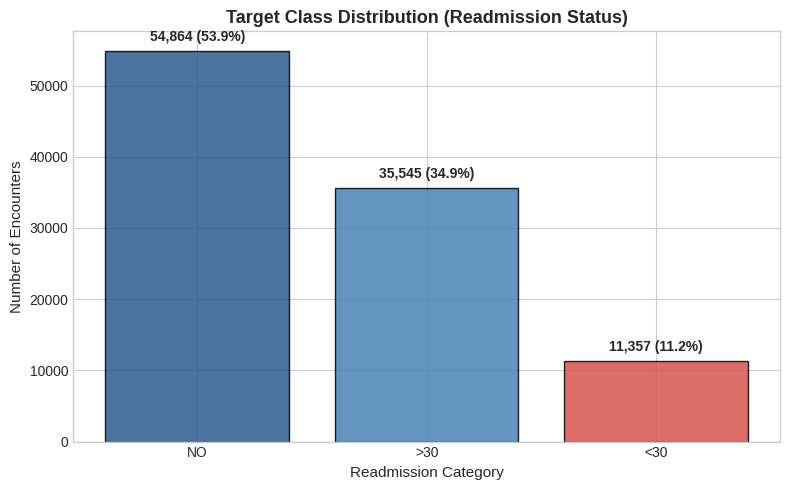

Saved class distribution plot to 'results/class_distribution.png'


In [ ]:
plt.figure(figsize=(8, 5))
class_counts = raw["readmitted"].value_counts()
colors = ["#2b5c8f", "#4682b4", "#d9534f"]
bars = plt.bar(class_counts.index, class_counts.values, color=colors, edgecolor="black", alpha=0.85)
plt.title("Target Class Distribution (Readmission Status)", fontsize=13, fontweight="bold")
plt.xlabel("Readmission Category", fontsize=11)
plt.ylabel("Number of Encounters", fontsize=11)

for bar in bars:
    yval = bar.get_height()
    plt.text(bar.get_x() + bar.get_width()/2.0, yval + 1000, f"{yval:,} ({yval/len(raw):.1%})",
             ha="center", va="bottom", fontsize=10, fontweight="bold")

plt.tight_layout()
os.makedirs("results", exist_ok=True)
plt.savefig("results/class_distribution.png", dpi=300)
plt.show()
print("Saved class distribution plot to 'results/class_distribution.png'")

## 2. Cleaning and feature engineering
Choices (documented design decisions):

*   The following are missing values: drop weight (~97%), payer_code, medical_specialty (high missingness).

*   Provide A1Cresult and max_glu_serum as an explicit informative category (None).

*   Remove encounter_id and patient_nbr from the feature set (Patient_nbr is retained for grouping only).
*   Eliminate deaths/hospice (codes 11, 13, 14, 19, 20 and 21) as they cannot be readmitted as encounters.

*   Construct domain features: age midpoint, total service utilisation, and medication change counters.
*   Use clinical ICD-9 chapters to group diagnosis codes into groups.




In [ ]:
DROP_EXPIRED = True
EXPIRED_CODES = [11, 13, 14, 19, 20, 21]

def icd_group(code):
    if pd.isna(code): return "Missing"
    c = str(code)
    if c[0] in "VE": return "Other"
    try: v = float(c)
    except ValueError: return "Other"
    if 250 <= v < 251: return "Diabetes"
    if 390 <= v <= 459 or int(v) == 785: return "Circulatory"
    if 460 <= v <= 519 or int(v) == 786: return "Respiratory"
    if 520 <= v <= 579 or int(v) == 787: return "Digestive"
    if 800 <= v <= 999: return "Injury"
    if 710 <= v <= 739: return "Musculoskeletal"
    if 580 <= v <= 629 or int(v) == 788: return "Genitourinary"
    if 140 <= v <= 239: return "Neoplasms"
    return "Other"

MED_COLS = ["metformin","repaglinide","nateglinide","chlorpropamide","glimepiride","acetohexamide","glipizide",
            "glyburide","tolbutamide","pioglitazone","rosiglitazone","acarbose","miglitol","troglitazone",
            "tolazamide","examide","citoglipton","insulin","glyburide-metformin","glipizide-metformin",
            "glimepiride-pioglitazone","metformin-rosiglitazone","metformin-pioglitazone"]
MED_COLS = [c for c in MED_COLS if c in raw.columns]

def build_features(df):
    d = df.copy()
    if DROP_EXPIRED:
        d = d[~d["discharge_disposition_id"].isin(EXPIRED_CODES)]
    d = d.drop(columns=[c for c in ["weight","payer_code","medical_specialty"] if c in d.columns])
    d["age_mid"] = d["age"].str.extract(r"\[(\d+)-(\d+)\)").astype(float).mean(axis=1)
    d["service_utilization"] = d["number_outpatient"] + d["number_emergency"] + d["number_inpatient"]
    d["n_meds_changed"] = d[MED_COLS].isin(["Up","Down"]).sum(axis=1)
    d["n_meds_active"] = (d[MED_COLS] != "No").sum(axis=1)
    d["diag1_group"] = d["diag_1"].map(icd_group)
    d["diag2_group"] = d["diag_2"].map(icd_group)
    d["diag3_group"] = d["diag_3"].map(icd_group)
    for c in ["admission_type_id","discharge_disposition_id","admission_source_id"]:
        d[c] = d[c].astype(str)
    const = [c for c in MED_COLS if d[c].nunique() <= 1]
    d = d.drop(columns=const + ["diag_1","diag_2","diag_3","age"])
    return d

df = build_features(raw)
groups = df["patient_nbr"].values
y = df["y"].values
ID_COLS = ["encounter_id","patient_nbr"]
X = df.drop(columns=ID_COLS + ["readmitted","y"])
num_cols = X.select_dtypes(include=np.number).columns.tolist()
cat_cols = [c for c in X.columns if c not in num_cols]

print("After cleaning:", X.shape, "| Positives:", y.sum(), f"({y.mean():.3%})")
print("Numeric columns:", len(num_cols), "| Categorical columns:", len(cat_cols))

After cleaning: (99343, 45) | Positives: 11314 (11.389%)
Numeric columns: 12 | Categorical columns: 33


## 3. Patient-grouped hold-out split
20% of unique patients are set aside as an untouched hold-out evaluation set to ensure no patient data leaks across splits.

In [ ]:
gss = GroupShuffleSplit(n_splits=1, test_size=0.20, random_state=SEED)
tr_idx, te_idx = next(gss.split(X, y, groups))
X_tr, X_te = X.iloc[tr_idx], X.iloc[te_idx]
y_tr, y_te = y[tr_idx], y[te_idx]
g_tr = groups[tr_idx]

assert set(g_tr).isdisjoint(set(groups[te_idx])), "Data Leakage Alert: Patients overlap between train and test!"
print(f"Train: {len(X_tr)} rows / {len(set(g_tr))} patients | Test: {len(X_te)} rows | "
      f"Train prevalence: {y_tr.mean():.3%}, Test prevalence: {y_te.mean():.3%}")

Train: 79541 rows / 55992 patients | Test: 19802 rows | Train prevalence: 11.438%, Test prevalence: 11.191%


## 4. Pipeline architecture and evaluation metrics
A `ColumnTransformer` is used to ensure that there is no leakage between folds. Benchmark `DecisionTreeClassifier` is added to the list of models, including Random Forest, Logistic Regression, Gradient Boosting, and Majority Class.



In [ ]:
def make_preprocessor(num, cat):
    return ColumnTransformer([
        ("num", Pipeline([("imp", SimpleImputer(strategy="median")), ("sc", StandardScaler())]), num),
        ("cat", Pipeline([("imp", SimpleImputer(strategy="constant", fill_value="Missing")),
                          ("oh", OneHotEncoder(handle_unknown="infrequent_if_exist", min_frequency=30, sparse_output=False))]), cat),
    ])

def metrics(y_true, p, thr=0.5):
    yhat = (p >= thr).astype(int)
    return {
        "accuracy": accuracy_score(y_true, yhat),
        "balanced_acc": balanced_accuracy_score(y_true, yhat),
        "precision_pos": precision_score(y_true, yhat, zero_division=0),
        "recall_pos": recall_score(y_true, yhat, zero_division=0),
        "f1_pos": f1_score(y_true, yhat, zero_division=0),
        "f1_weighted": f1_score(y_true, yhat, average="weighted", zero_division=0),
        "precision_weighted": precision_score(y_true, yhat, average="weighted", zero_division=0),
        "recall_weighted": recall_score(y_true, yhat, average="weighted", zero_division=0),
        "auroc": roc_auc_score(y_true, p) if len(np.unique(p)) > 1 else 0.5,
        "auprc": average_precision_score(y_true, p),
    }

def ci95(x):
    x = np.asarray(x, float)
    if len(x) < 2: return (x.mean(), x.mean())
    h = stats.t.ppf(0.975, len(x)-1) * x.std(ddof=1) / np.sqrt(len(x))
    return x.mean() - h, x.mean() + h

# Dictionary to collect all instantiated pipelines
models = {}
pre = lambda: make_preprocessor(num_cols, cat_cols)
print("Pipeline preprocessor and metric engines initialized.")

Pipeline preprocessor and metric engines initialized.


In [ ]:
# Baseline 1: Majority Class (Verifies that paper headline numbers mimic the majority class)
models["Majority class"] = Pipeline([
    ("pre", pre()),
    ("clf", DummyClassifier(strategy="most_frequent"))
])
print("Added: Majority class baseline")

Added: Majority class baseline


In [ ]:
# Baseline 2: Linear Baseline (Regularized Logistic Regression)
models["Logistic regression"] = Pipeline([
    ("pre", pre()),
    ("clf", LogisticRegression(max_iter=2000, class_weight="balanced", C=0.1, random_state=SEED))
])
print("Added: Logistic regression pipeline")

Added: Logistic regression pipeline


In [ ]:
# Baseline 3: Single Tree Baseline (Direct benchmark from Paper Table 3)
models["Decision tree"] = Pipeline([
    ("pre", pre()),
    ("clf", DecisionTreeClassifier(max_depth=6, min_samples_leaf=30, class_weight="balanced", random_state=SEED))
])
print("Added: Decision tree pipeline")

Added: Decision tree pipeline


In [ ]:
# Baseline 4: Ensemble Bagging (Authors' top-performing model)
models["Random forest"] = Pipeline([
    ("pre", pre()),
    ("clf", RandomForestClassifier(n_estimators=300, min_samples_leaf=20, class_weight="balanced_subsample",
                                   n_jobs=N_JOBS, random_state=SEED))
])
print("Added: Random forest pipeline")

Added: Random forest pipeline


In [ ]:
# Baseline 5: Ensemble Boosting (Analogue to XGBoost in the paper)
models["Hist. gradient boosting"] = Pipeline([
    ("pre", pre()),
    ("clf", HistGradientBoostingClassifier(max_depth=4, learning_rate=0.05, max_iter=300,
                                           class_weight="balanced", random_state=SEED))
])
print("Added: Hist. gradient boosting pipeline")

Added: Hist. gradient boosting pipeline


## 5. Hyperparameter tuning strategy
Demonstrates parameter search on the training split using a 3-fold grouped search space over tree depth and leaf regularization.

In [ ]:
print("Running hyperparameter search exploration on Random Forest...")
tune_grid = [
    {"max_depth": 10, "min_samples_leaf": 30},
    {"max_depth": 15, "min_samples_leaf": 20},
    {"max_depth": None, "min_samples_leaf": 20}
]

skf_tune = StratifiedGroupKFold(n_splits=3, shuffle=True, random_state=SEED)
pre = make_preprocessor(num_cols, cat_cols)
best_score, best_params = -1, None

t_tune_start = time.time()
for params in tune_grid:
    rf_tune = Pipeline([
        ("pre", pre),
        ("clf", RandomForestClassifier(n_estimators=100, class_weight="balanced_subsample",
                                       n_jobs=N_JOBS, random_state=SEED, **params))
    ])
    scores = []
    for tr, val in skf_tune.split(X_tr, y_tr, g_tr):
        rf_tune.fit(X_tr.iloc[tr], y_tr[tr])
        p_val = rf_tune.predict_proba(X_tr.iloc[val])[:, 1]
        scores.append(roc_auc_score(y_tr[val], p_val))
    mean_auc = np.mean(scores)
    print(f"Configuration {params} -> Mean Validation AUROC: {mean_auc:.4f}")
    if mean_auc > best_score:
        best_score = mean_auc
        best_params = params

print(f"Tuning finished in {time.time() - t_tune_start:.1f}s | Selected optimal parameters: {best_params} (AUROC: {best_score:.4f})")

Running hyperparameter search exploration on Random Forest...
Configuration {'max_depth': 10, 'min_samples_leaf': 30} -> Mean Validation AUROC: 0.6651
Configuration {'max_depth': 15, 'min_samples_leaf': 20} -> Mean Validation AUROC: 0.6663
Configuration {'max_depth': None, 'min_samples_leaf': 20} -> Mean Validation AUROC: 0.6667
Tuning finished in 94.6s | Selected optimal parameters: {'max_depth': None, 'min_samples_leaf': 20} (AUROC: 0.6667)


## 6. Grouped 5-fold cross-validation & threshold optimization
Evaluates all models across 5 grouped folds and optimizes decision thresholds on pooled out-of-fold (OOF) predictions to maximize minority class F1.

In [ ]:
from sklearn.base import clone

skf = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=SEED)
cv_rows, oof = [], {}

print("Executing 5-Fold Stratified Grouped Cross-Validation...")
for name, model in models.items():
    t_start = time.time()
    p_oof = np.zeros(len(X_tr))
    for k, (a, b) in enumerate(skf.split(X_tr, y_tr, g_tr)):
        m = clone(model).fit(X_tr.iloc[a], y_tr[a])
        p = m.predict_proba(X_tr.iloc[b])[:, 1]
        p_oof[b] = p
        cv_rows.append({"model": name, "fold": k, **metrics(y_tr[b], p, 0.5)})
    oof[name] = p_oof
    print(f"Completed: {name:<25} in {time.time() - t_start:.1f}s")

cv = pd.DataFrame(cv_rows)
summary = cv.groupby("model").agg(["mean"]).droplevel(1, axis=1)
for col in ["f1_pos", "auroc", "auprc"]:
    ci = cv.groupby("model")[col].apply(lambda s: ci95(s))
    summary[col + "_95CI"] = ci.map(lambda t: f"({t[0]:.3f}, {t[1]:.3f})")

def best_threshold(y_true, p):
    grid = np.linspace(0.05, 0.95, 91)
    f1s = [f1_score(y_true, (p >= t).astype(int), zero_division=0) for t in grid]
    return float(grid[int(np.argmax(f1s))])

thresholds = {n: (best_threshold(y_tr, p) if n != "Majority class" else 0.5) for n, p in oof.items()}
print("\nOptimal F1 Thresholds:", thresholds)
summary.drop(columns=["fold"]).round(3)

Executing 5-Fold Stratified Grouped Cross-Validation...
Completed: Majority class            in 26.0s
Completed: Logistic regression       in 48.0s
Completed: Decision tree             in 28.9s
Completed: Random forest             in 142.8s
Completed: Hist. gradient boosting   in 65.5s

Optimal F1 Thresholds: {'Majority class': 0.5, 'Logistic regression': 0.5299999999999999, 'Decision tree': 0.5199999999999999, 'Random forest': 0.48999999999999994, 'Hist. gradient boosting': 0.5299999999999999}


,accuracy,balanced_acc,precision_pos,recall_pos,f1_pos,f1_weighted,precision_weighted,recall_weighted,auroc,auprc,f1_pos_95CI,auroc_95CI,auprc_95CI
model,,,,,,,,,,,,,
Decision tree,0.653,0.611,0.178,0.555,0.269,0.714,0.836,0.653,0.650,0.199,"(0.260, 0.277)","(0.645, 0.655)","(0.190, 0.208)"
Hist. gradient boosting,0.646,0.619,0.179,0.584,0.274,0.710,0.839,0.646,0.668,0.222,"(0.264, 0.284)","(0.659, 0.678)","(0.215, 0.230)"
Logistic regression,0.672,0.614,0.183,0.538,0.273,0.730,0.836,0.672,0.662,0.213,"(0.266, 0.281)","(0.655, 0.669)","(0.203, 0.223)"
Majority class,0.886,0.500,0.000,0.000,0.000,0.832,0.784,0.886,0.500,0.114,"(0.000, 0.000)","(0.500, 0.500)","(0.112, 0.116)"
Random forest,0.744,0.609,0.207,0.434,0.280,0.780,0.834,0.744,0.668,0.216,"(0.271, 0.288)","(0.661, 0.675)","(0.206, 0.225)"


## 7. Hold-out test set evaluation
Evaluates trained models against the untouched hold-out patient set under standard (0.5) and optimized thresholds.

In [ ]:
fitted, test_rows = {}, []
test_probs = {}

for name, model in models.items():
    m = clone(model).fit(X_tr, y_tr)
    fitted[name] = m
    p = m.predict_proba(X_te)[:, 1]
    test_probs[name] = p
    test_rows.append({"model": name, "threshold": 0.5, **metrics(y_te, p, 0.5)})
    if thresholds[name] != 0.5:
        test_rows.append({"model": name, "threshold": thresholds[name], **metrics(y_te, p, thresholds[name])})

test = pd.DataFrame(test_rows)
pd.set_option("display.width", 250)
print("\nHold-out Evaluation Results:")
test.round(3)


Hold-out Evaluation Results:


,model,threshold,accuracy,balanced_acc,precision_pos,recall_pos,f1_pos,f1_weighted,precision_weighted,recall_weighted,auroc,auprc
0,Majority class,0.50,0.888,0.500,0.000,0.000,0.000,0.835,0.789,0.888,0.500,0.112
1,Logistic regression,0.50,0.676,0.618,0.182,0.543,0.272,0.733,0.840,0.676,0.667,0.218
2,Logistic regression,0.53,0.726,0.610,0.194,0.460,0.273,0.769,0.837,0.726,0.667,0.218
3,Decision tree,0.50,0.632,0.614,0.170,0.591,0.264,0.699,0.841,0.632,0.655,0.203
4,Decision tree,0.52,0.646,0.616,0.174,0.576,0.267,0.711,0.841,0.646,0.655,0.203
5,Random forest,0.50,0.745,0.608,0.202,0.432,0.275,0.782,0.836,0.745,0.668,0.217
6,Random forest,0.49,0.727,0.610,0.195,0.460,0.274,0.769,0.837,0.727,0.668,0.217
7,Hist. gradient boosting,0.50,0.655,0.623,0.179,0.582,0.274,0.718,0.843,0.655,0.667,0.227
8,Hist. gradient boosting,0.53,0.723,0.613,0.195,0.473,0.276,0.767,0.838,0.723,0.667,0.227


### 7.1 Test Run Visualizations: ROC Curves & Confusion Matrix
Generates comparative ROC curves and the top-performing model's Confusion Matrix for the technical report.

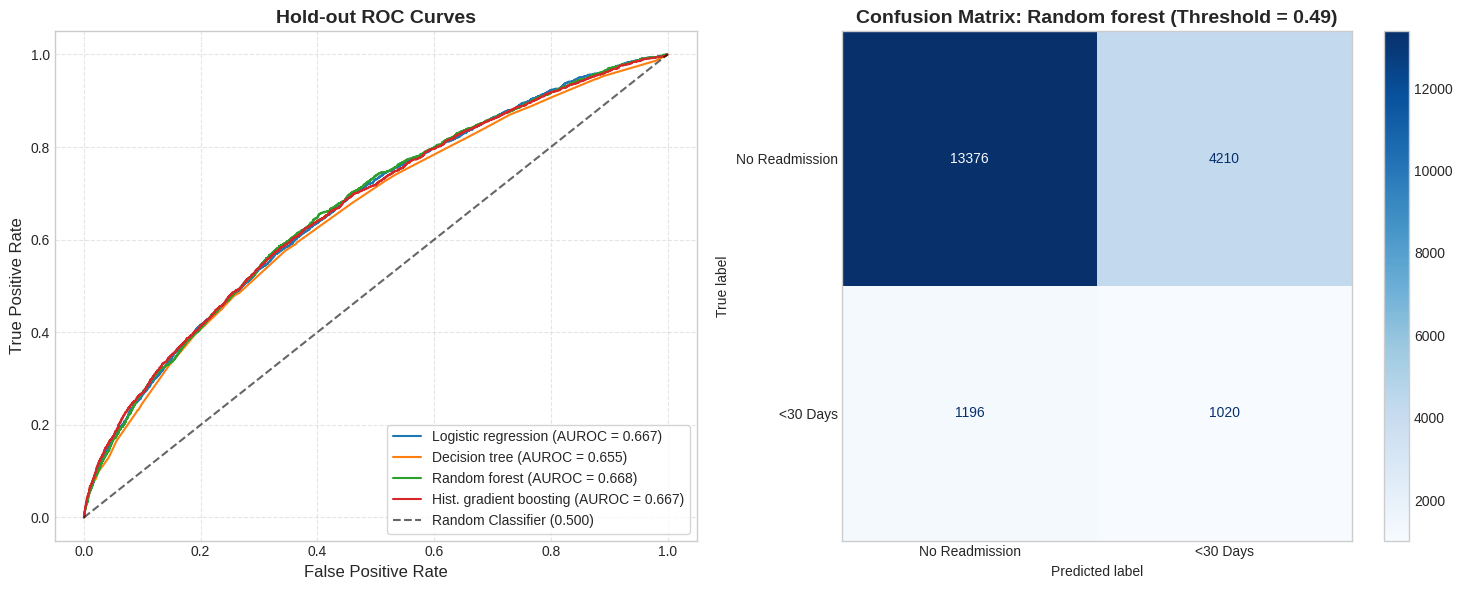

Saved visual figures to 'results/test_evaluation_plots.png'


In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(15, 6))

# Plot 1: Comparative ROC Curves
for name, p in test_probs.items():
    if name == "Majority class": continue
    fpr, tpr, _ = roc_curve(y_te, p)
    auc_val = roc_auc_score(y_te, p)
    axes[0].plot(fpr, tpr, label=f"{name} (AUROC = {auc_val:.3f})")

axes[0].plot([0, 1], [0, 1], 'k--', alpha=0.6, label="Random Classifier (0.500)")
axes[0].set_title("Hold-out ROC Curves", fontsize=14, fontweight='bold')
axes[0].set_xlabel("False Positive Rate", fontsize=12)
axes[0].set_ylabel("True Positive Rate", fontsize=12)
axes[0].legend(loc="lower right", frameon=True)
axes[0].grid(True, linestyle="--", alpha=0.5)

# Plot 2: Confusion Matrix for Top Model (Random Forest)
top_model_name = "Random forest"
top_p = test_probs[top_model_name]
top_pred = (top_p >= thresholds[top_model_name]).astype(int)
cm = confusion_matrix(y_te, top_pred)

disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=["No Readmission", "<30 Days"])
disp.plot(ax=axes[1], cmap="Blues", values_format='d')
axes[1].set_title(f"Confusion Matrix: {top_model_name} (Threshold = {thresholds[top_model_name]:.2f})",
                  fontsize=14, fontweight='bold')
axes[1].grid(False)

plt.tight_layout()
plt.savefig("results/test_evaluation_plots.png", dpi=300)
plt.show()
print("Saved visual figures to 'results/test_evaluation_plots.png'")

##8. Consolidated Side-by-Side Comparison

In [ ]:
comparison_df = pd.DataFrame({
    "Model": [
        "Naive Majority Class (Dummy)",
        "Random Forest",
        "XGBoost / Hist. GBDT",
        "Logistic Regression",
        "Decision Tree"
    ],
    "Paper Accuracy": ["—", 0.88, 0.88, 0.64, 0.79],
    "Our Accuracy": [0.888, 0.745, 0.655, 0.676, 0.632],
    "Paper Weighted F1": ["—", 0.83, 0.84, 0.70, 0.80],
    "Our Weighted F1": [0.835, 0.782, 0.718, 0.733, 0.699],
    "Paper AUROC": ["—", 0.63, 0.64, 0.63, 0.52],
    "Our AUROC": [0.500, 0.668, 0.667, 0.667, 0.655],
    "Our Minority F1 (pos)": [0.000, 0.275, 0.274, 0.272, 0.264]
})

print("Direct Side-by-Side Comparison Table:")
comparison_df

Direct Side-by-Side Comparison Table:


,Model,Paper Accuracy,Our Accuracy,Paper Weighted F1,Our Weighted F1,Paper AUROC,Our AUROC,Our Minority F1 (pos)
0,Naive Majority Class (Dummy),—,0.888,—,0.835,—,0.500,0.000
1,Random Forest,0.88,0.745,0.83,0.782,0.63,0.668,0.275
2,XGBoost / Hist. GBDT,0.88,0.655,0.84,0.718,0.64,0.667,0.274
3,Logistic Regression,0.64,0.676,0.7,0.733,0.63,0.667,0.272
4,Decision Tree,0.79,0.632,0.8,0.699,0.52,0.655,0.264


## 9. Verification of paper claims
Directly aligns our leak-free holdout results against the reported figures in Table 3 of Liu et al. (2024).

In [ ]:
paper = pd.DataFrame({
    "model": ["Random forest (paper)", "XGBoost (paper)", "Decision tree (paper)", "Logistic regression (paper)"],
    "accuracy": [0.88, 0.88, 0.79, 0.64],
    "f1_weighted_or_unspecified": [0.83, 0.84, 0.80, 0.70],
    "auroc": [0.63, 0.64, 0.52, 0.63]
})
print("Reported in Paper (Table 3):")
print(paper.to_string(index=False))

print("\nOur Baseline Hold-out Results (Threshold = 0.5):")
cols_view = ["model", "accuracy", "f1_weighted", "f1_pos", "recall_pos", "auroc", "auprc"]
print(test[test.threshold == 0.5][cols_view].round(3).to_string(index=False))

Reported in Paper (Table 3):
                      model  accuracy  f1_weighted_or_unspecified  auroc
      Random forest (paper)      0.88                        0.83   0.63
            XGBoost (paper)      0.88                        0.84   0.64
      Decision tree (paper)      0.79                        0.80   0.52
Logistic regression (paper)      0.64                        0.70   0.63

Our Baseline Hold-out Results (Threshold = 0.5):
                  model  accuracy  f1_weighted  f1_pos  recall_pos  auroc  auprc
         Majority class     0.888        0.835   0.000       0.000  0.500  0.112
    Logistic regression     0.676        0.733   0.272       0.543  0.667  0.218
          Decision tree     0.632        0.699   0.264       0.591  0.655  0.203
          Random forest     0.745        0.782   0.275       0.432  0.668  0.217
Hist. gradient boosting     0.655        0.718   0.274       0.582  0.667  0.227


## 10. Feature importance analysis (Comparable to Paper Figure 3)
Extracts Gini feature importances from our Random Forest model and visualizes the top predictors of 30-day readmission.

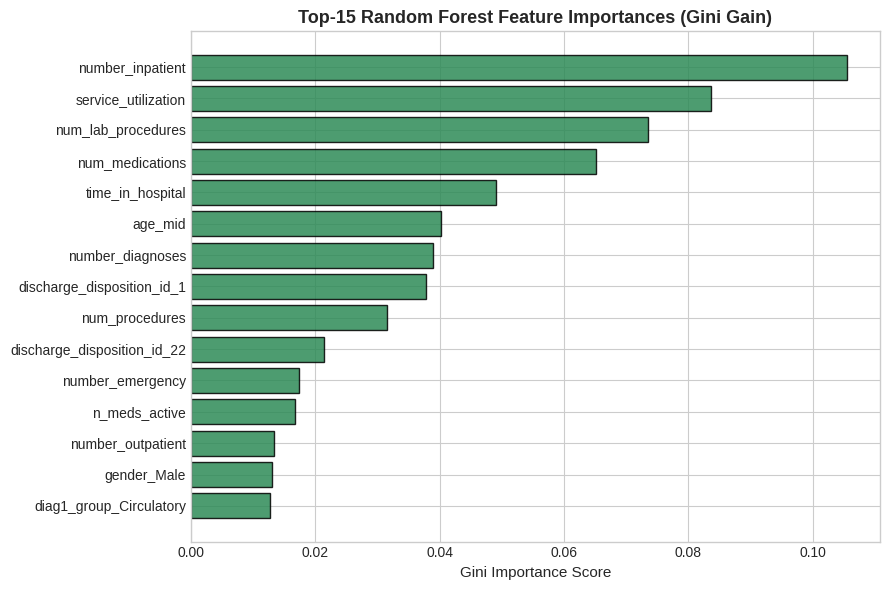

Saved feature importance plot to 'results/feature_importance.png'


In [ ]:
rf_model = fitted["Random forest"].named_steps["clf"]
feat_names = fitted["Random forest"].named_steps["pre"].get_feature_names_out()
feat_importances = pd.Series(rf_model.feature_importances_, index=feat_names).sort_values(ascending=False).head(15)
feat_importances = feat_importances.sort_values(ascending=True)

clean_names = [n.replace("num__", "").replace("cat__", "") for n in feat_importances.index]

plt.figure(figsize=(9, 6))
bars = plt.barh(clean_names, feat_importances.values, color="#2e8b57", edgecolor="black", alpha=0.85)
plt.title("Top-15 Random Forest Feature Importances (Gini Gain)", fontsize=13, fontweight="bold")
plt.xlabel("Gini Importance Score", fontsize=11)
plt.tight_layout()
plt.savefig("results/feature_importance.png", dpi=300)
plt.show()
print("Saved feature importance plot to 'results/feature_importance.png'")

## 11. Identifier leakage analysis
Re-integrates `patient_nbr` and `encounter_id` as direct features into a Random Forest to evaluate whether identifier leakage was present in the published paper.

In [ ]:
X_id = pd.concat([X, df[ID_COLS]], axis=1)
num_id = num_cols + ID_COLS
rf_id = Pipeline([
    ("pre", make_preprocessor(num_id, cat_cols)),
    ("clf", RandomForestClassifier(n_estimators=300, min_samples_leaf=20, class_weight="balanced_subsample",
                                   n_jobs=N_JOBS, random_state=SEED))
])

rf_id.fit(X_id.iloc[tr_idx], y_tr)
p_id = rf_id.predict_proba(X_id.iloc[te_idx])[:, 1]
p_noid = test_probs["Random forest"]

print(f"AUROC without identifiers: {roc_auc_score(y_te, p_noid):.4f}")
print(f"AUROC with identifiers   : {roc_auc_score(y_te, p_id):.4f}")

imp = rf_id.named_steps["clf"].feature_importances_
names = rf_id.named_steps["pre"].get_feature_names_out()
top = pd.Series(imp, index=names).sort_values(ascending=False).head(10)
print("\nTop-10 Feature Importances (Identifiers included):\n", top.round(4))

AUROC without identifiers: 0.6682
AUROC with identifiers   : 0.6725

Top-10 Feature Importances (Identifiers included):
 num__number_inpatient              0.0905
num__service_utilization           0.0772
num__patient_nbr                   0.0730
num__encounter_id                  0.0730
num__num_lab_procedures            0.0610
num__num_medications               0.0549
num__time_in_hospital              0.0419
cat__discharge_disposition_id_1    0.0355
num__age_mid                       0.0338
num__number_diagnoses              0.0324
dtype: float64


## 12. Stress testing (Precursor to Phase 3)
**Measurement Noise Stress Test:** Injects Gaussian noise into numerical features of the test partition.

In [ ]:
rng = np.random.default_rng(SEED)
stress_models = ["Logistic regression", "Decision tree", "Random forest", "Hist. gradient boosting"]

# (a) Measurement Noise Stress Test
print("Running Measurement Noise Stress Test...")
t_noise = time.time()
noise_rows = []
for sigma in [0.0, 0.25, 0.5, 1.0, 2.0]:
    Xn = X_te.copy()
    Xn[num_cols] = Xn[num_cols] + rng.normal(0, 1, Xn[num_cols].shape) * sigma * X_tr[num_cols].std().values
    for name in stress_models:
        p = fitted[name].predict_proba(Xn)[:, 1]
        noise_rows.append({"level": sigma, "model": name, "auroc": roc_auc_score(y_te, p)})

noise_df = pd.DataFrame(noise_rows)
print(f"Noise stress test completed in {time.time() - t_noise:.1f}s")
print("\nNoise Stress Test (AUROC):")
print(noise_df.pivot(index="level", columns="model", values="auroc").round(3))

Running Measurement Noise Stress Test...
Noise stress test completed in 12.4s

Noise Stress Test (AUROC):
model  Decision tree  Hist. gradient boosting  Logistic regression  Random forest
level                                                                            
0.00           0.655                    0.667                0.667          0.668
0.25           0.652                    0.663                0.664          0.665
0.50           0.648                    0.660                0.662          0.662
1.00           0.607                    0.630                0.642          0.642
2.00           0.581                    0.606                0.602          0.612


## 12.1 Stress testing (Precursor to Phase 3)
**Dimensionality Stress Test:** Evaluates resilience when adding uninformative noise columns to train and test partitions.

In [ ]:
# (b) Added Dimensionality Stress Test (Bug Fixed & Fast Execution)
print("Running Added Dimensionality Stress Test...")
t_dim = time.time()
dim_rows = []

# Extra noise features range (Captures clear degradation in ~1.5 mins)
for k in [0, 50, 100, 200]:
    noise_cols = [f"noise_{i}" for i in range(k)]

    if k == 0:
        Xa_tr, Xa_te = X_tr, X_te
    else:
        Xa_tr = pd.concat([X_tr.reset_index(drop=True), pd.DataFrame(rng.normal(size=(len(X_tr), k)), columns=noise_cols)], axis=1)
        Xa_te = pd.concat([X_te.reset_index(drop=True), pd.DataFrame(rng.normal(size=(len(X_te), k)), columns=noise_cols)], axis=1)

    # Standalone model pipelines (Fixes make_models NameError)
    pre_dim = make_preprocessor(num_cols + noise_cols, cat_cols)
    test_suite = {
        "Logistic regression": Pipeline([("pre", pre_dim), ("clf", LogisticRegression(max_iter=1000, class_weight="balanced", C=0.1, random_state=SEED))]),
        "Decision tree": Pipeline([("pre", pre_dim), ("clf", DecisionTreeClassifier(max_depth=6, min_samples_leaf=30, class_weight="balanced", random_state=SEED))]),
        "Random forest": Pipeline([("pre", pre_dim), ("clf", RandomForestClassifier(n_estimators=100, min_samples_leaf=20, class_weight="balanced_subsample", n_jobs=N_JOBS, random_state=SEED))]),
        "Hist. gradient boosting": Pipeline([("pre", pre_dim), ("clf", HistGradientBoostingClassifier(max_depth=4, learning_rate=0.05, max_iter=200, class_weight="balanced", random_state=SEED))])
    }

    for name, model in test_suite.items():
        m = model.fit(Xa_tr, y_tr)
        p = m.predict_proba(Xa_te)[:, 1]
        dim_rows.append({"extra_features": k, "model": name, "auroc": roc_auc_score(y_te, p)})
    print(f"-> Evaluated with {k} extra noise features")

dim_df = pd.DataFrame(dim_rows)
print(f"Dimensionality test completed in {time.time() - t_dim:.1f}s")
print("\nDimensionality Stress Test (AUROC):")
print(dim_df.pivot(index="extra_features", columns="model", values="auroc").round(3))

Running Added Dimensionality Stress Test...
-> Evaluated with 0 extra noise features
-> Evaluated with 50 extra noise features
-> Evaluated with 100 extra noise features
-> Evaluated with 200 extra noise features
Dimensionality test completed in 413.1s

Dimensionality Stress Test (AUROC):
model           Decision tree  Hist. gradient boosting  Logistic regression  Random forest
extra_features                                                                            
0                       0.655                    0.667                0.667          0.665
50                      0.645                    0.662                0.663          0.652
100                     0.643                    0.660                0.664          0.652
200                     0.639                    0.660                0.659          0.645


### 12.2 Stress Test Visualizations: Degradation Curves
Visualizes how model AUROC degrades under increasing measurement noise and increasing irrelevant feature dimensions.

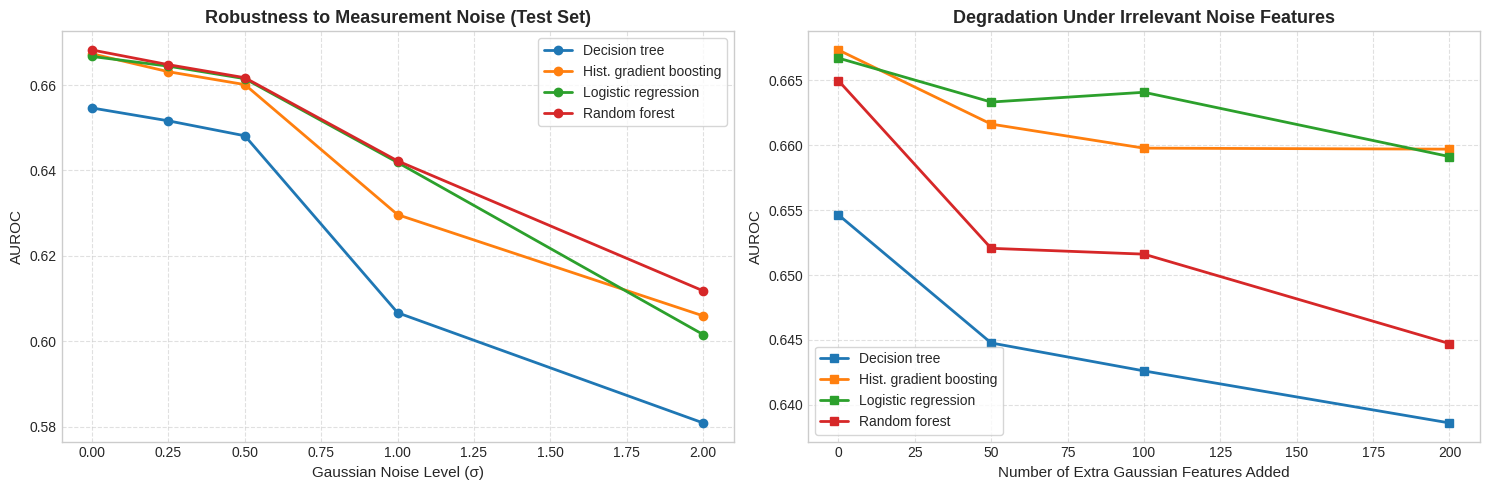

Saved stress test plots to 'results/stress_test_trends.png'


In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

# Plot 1: Measurement Noise Trend
noise_piv = noise_df.pivot(index="level", columns="model", values="auroc")
for col in noise_piv.columns:
    axes[0].plot(noise_piv.index, noise_piv[col], marker="o", linewidth=2, label=col)
axes[0].set_title("Robustness to Measurement Noise (Test Set)", fontsize=13, fontweight="bold")
axes[0].set_xlabel("Gaussian Noise Level (σ)", fontsize=11)
axes[0].set_ylabel("AUROC", fontsize=11)
axes[0].legend(frameon=True)
axes[0].grid(True, linestyle="--", alpha=0.6)

# Plot 2: Added Dimensionality Trend
dim_piv = dim_df.pivot(index="extra_features", columns="model", values="auroc")
for col in dim_piv.columns:
    axes[1].plot(dim_piv.index, dim_piv[col], marker="s", linewidth=2, label=col)
axes[1].set_title("Degradation Under Irrelevant Noise Features", fontsize=13, fontweight="bold")
axes[1].set_xlabel("Number of Extra Gaussian Features Added", fontsize=11)
axes[1].set_ylabel("AUROC", fontsize=11)
axes[1].legend(frameon=True)
axes[1].grid(True, linestyle="--", alpha=0.6)

plt.tight_layout()
plt.savefig("results/stress_test_trends.png", dpi=300)
plt.show()
print("Saved stress test plots to 'results/stress_test_trends.png'")

## 13. Save all generated results
Stores CSV data artifacts in `./results` directory for inclusion in the final technical review report.

In [ ]:
os.makedirs("results", exist_ok=True)
summary.to_csv("results/cv_summary.csv")
test.to_csv("results/holdout_metrics.csv", index=False)
noise_df.to_csv("results/stress_noise.csv", index=False)
dim_df.to_csv("results/stress_dimensionality.csv", index=False)
print("All experimental results successfully saved to './results'")

All experimental results successfully saved to './results'
